# Part 2 Dataset EDA · Open Food Facts Nutrient Detection Layout

**Dataset ID:** `openfoodfacts/nutrient-detection-layout`.

This standalone notebook profiles the **actual Part 2 annotated dataset** from the official Hugging Face train/test splits. It requests bounded pages of annotation metadata and OCR sequences, but **never downloads image payloads** or the full repository parquet files.

> **Schema caveat:** this dataset is a token-classification corpus (`tokens`, `bboxes`, `ner_tags`, `image`, `meta`), not a product nutrition fact table. It has no structured calories/fat/sugar columns and no brand/category/packaging fields. Nutrition value/unit mentions can be summarized by their annotated BIO entity class, but cannot always be linked to nutrient names because nutrient names are generally tagged `O`.

The notebook validates the live schema/revision, official splits, barcode quality/leakage, token/box/tag alignment, bounding boxes, label distribution, OCR sequence lengths, annotation flags, and tagged numeric-value distributions. Outputs are saved under `reports/part2_eda/` for the dashboard's separate Part 2 view. Test split labels are descriptive only and must not be used to tune extraction rules.

## 1. Load the Part 2 dataset and validate schema

Read current dataset metadata first; then page through the exact official train and test splits. Each row request is bounded to 100 and keeps only token counts, BIO IDs, boxes, dimensions, and selected `meta` fields. The returned signed image URL is deliberately discarded.

In [21]:
from __future__ import annotations

import json
import math
import re
import time
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.parse import urlencode
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

DATASET_ID = "openfoodfacts/nutrient-detection-layout"
API_ROOT = "https://datasets-server.huggingface.co"
PAGE_SIZE = 100
OUTPUT_DIR = Path.cwd().resolve()
if OUTPUT_DIR.name == "part2":
    PROJECT_ROOT = OUTPUT_DIR.parent
else:
    PROJECT_ROOT = OUTPUT_DIR
    OUTPUT_DIR = PROJECT_ROOT / "part2"
if not (PROJECT_ROOT / "app.py").is_file() and (PROJECT_ROOT.parent / "app.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
OUTPUT_DIR = PROJECT_ROOT / "reports" / "part2_eda"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def get_json(url: str, retries: int = 4) -> dict:
    request = Request(url, headers={"User-Agent": "nutrition-extraction-part2-eda/0.1"})
    last_error = None
    for attempt in range(retries):
        try:
            with urlopen(request, timeout=60) as response:
                return json.loads(response.read().decode("utf-8"))
        except (HTTPError, URLError, TimeoutError, json.JSONDecodeError) as error:
            last_error = error
            time.sleep(attempt + 1)
    raise RuntimeError(f"Hugging Face metadata request failed after {retries} attempts: {last_error}")


hub_metadata = get_json(f"https://huggingface.co/api/datasets/{DATASET_ID}")
card_data = hub_metadata.get("cardData", {}).get("dataset_info", {})
split_counts = {row["name"]: int(row["num_examples"]) for row in card_data.get("splits", [])}
features = card_data.get("features", [])
feature_names = [feature.get("name", "") for feature in features]
label_feature = next((feature for feature in features if feature.get("name") == "ner_tags"), {})
label_map_raw = label_feature.get("sequence", {}).get("class_label", {}).get("names", {})
if isinstance(label_map_raw, dict):
    id_to_label = {int(key): str(value) for key, value in label_map_raw.items()}
else:
    id_to_label = {index: str(value) for index, value in enumerate(label_map_raw)}
license_id = card_data.get("license") or next(
    (tag.split(":", 1)[1] for tag in hub_metadata.get("tags", []) if tag.startswith("license:")),
    "not specified in API metadata",
)

print({
    "dataset": hub_metadata.get("id"),
    "revision": hub_metadata.get("sha"),
    "last_modified": hub_metadata.get("lastModified"),
    "license": license_id,
    "splits": split_counts,
    "top_level_features": feature_names,
    "BIO_class_count": len(id_to_label),
    "output_directory": str(OUTPUT_DIR),
})
display(pd.DataFrame([{"feature": item.get("name"), "feature_type": json.dumps({k:v for k,v in item.items() if k != "name"}, ensure_ascii=False)[:240]} for item in features]))

{'dataset': 'openfoodfacts/nutrient-detection-layout', 'revision': '7d3245ca596f0c8f41dc740ca0fa5987b1e0fd4d', 'last_modified': '2024-12-23T18:06:29.000Z', 'license': 'cc-by-sa-3.0', 'splits': {'train': 2884, 'test': 199}, 'top_level_features': ['ner_tags', 'tokens', 'bboxes', 'image', 'meta'], 'BIO_class_count': 71, 'output_directory': 'C:\\Users\\SaniaJawaid\\Documents\\projects\\practice\\study\\nutrition_extraction_solution\\reports\\part2_eda'}


,feature,feature_type
0,ner_tags,"{""sequence"": {""class_label"": {""names"": {""0"": ""..."
1,tokens,"{""sequence"": ""string""}"
2,bboxes,"{""sequence"": {""sequence"": ""int64""}}"
3,image,"{""dtype"": ""image""}"
4,meta,"{""struct"": [{""name"": ""barcode"", ""dtype"": ""stri..."


## 2. Inspect dtypes, missing values, duplicates, and malformed rows

The next cell fetches only the two published splits and derives compact per-example metadata. Token strings and numeric label IDs stay in memory during the analysis; source images are not opened or downloaded.

In [22]:
def valid_barcode(value) -> str | None:
    if value is None:
        return None
    barcode = str(value).strip()
    return barcode if barcode.isdigit() else None


def fetch_split_rows(split: str, expected_count: int) -> list[dict]:
    collected = []
    offset = 0
    while offset < expected_count:
        query = urlencode({"dataset": DATASET_ID, "config": "default", "split": split, "offset": offset, "length": PAGE_SIZE})
        payload = get_json(f"{API_ROOT}/rows?{query}")
        if int(payload.get("num_rows_total", -1)) != expected_count:
            raise RuntimeError(f"HF row endpoint count changed for {split}: {payload.get('num_rows_total')} != {expected_count}")
        page = payload.get("rows", [])
        if not page:
            raise RuntimeError(f"HF returned an empty page before all {split} records were read (offset={offset}).")
        for item in page:
            row = item.get("row", {})
            meta = row.get("meta") or {}
            image = row.get("image") or {}
            tokens = row.get("tokens") or []
            boxes = row.get("bboxes") or []
            tags = row.get("ner_tags") or []
            barcode_raw = meta.get("barcode")
            barcode = valid_barcode(barcode_raw)
            valid_boxes = [box for box in boxes if isinstance(box, (list, tuple)) and len(box) == 4]
            coords = [coordinate for box in valid_boxes for coordinate in box if isinstance(coordinate, (int, float))]
            alignment_ok = len(tokens) == len(boxes) == len(tags)
            normalized_coordinates = bool(coords) and all(0 <= coordinate <= 1000 for coordinate in coords)
            label_ids_valid = all(isinstance(tag, int) and tag in id_to_label for tag in tags)
            collected.append({
                "split": split,
                "barcode_raw": "" if barcode_raw is None else str(barcode_raw),
                "barcode": barcode or "",
                "image_id": str(meta.get("image_id") or ""),
                "image_url_present": bool(meta.get("image_url")),
                "ocr_url_present": bool(meta.get("ocr_url")),
                "batch": str(meta.get("batch") or ""),
                "label_studio_id": meta.get("label_studio_id"),
                "checked": meta.get("checked"),
                "usda_table": meta.get("usda_table"),
                "nutrition_text": meta.get("nutrition_text"),
                "no_nutrition_table": meta.get("no_nutrition_table"),
                "comment_present": bool(str(meta.get("comment") or "").strip()),
                "token_count": len(tokens),
                "bbox_count": len(boxes),
                "tag_count": len(tags),
                "sequence_alignment_ok": alignment_ok,
                "bbox_shape_ok": len(valid_boxes) == len(boxes),
                "bbox_coordinates_0_to_1000": normalized_coordinates,
                "label_ids_valid": label_ids_valid,
                "image_width": image.get("width") if isinstance(image, dict) else None,
                "image_height": image.get("height") if isinstance(image, dict) else None,
                # Keep OCR/labels only in memory for EDA counts and value summaries.
                "_tokens": [str(token) for token in tokens],
                "_ner_tags": [int(tag) for tag in tags if isinstance(tag, int)],
                "_boxes": boxes,
            })
        offset += len(page)
        print(f"Read metadata: {split} {min(offset, expected_count):,}/{expected_count:,}")
    if len(collected) != expected_count:
        raise RuntimeError(f"Fetched {len(collected)} {split} rows; expected {expected_count}.")
    return collected


split_rows = {split: fetch_split_rows(split, count) for split, count in split_counts.items()}
records = [record for split in ("train", "test") for record in split_rows.get(split, [])]
examples_df = pd.DataFrame([{key: value for key, value in item.items() if not key.startswith("_")} for item in records])
assert len(examples_df) == sum(split_counts.values())
print("Loaded metadata rows only:", examples_df.shape, "| downloaded images: 0")
display(examples_df.head())

Read metadata: train 100/2,884
Read metadata: train 200/2,884
Read metadata: train 300/2,884
Read metadata: train 400/2,884
Read metadata: train 500/2,884
Read metadata: train 600/2,884
Read metadata: train 700/2,884
Read metadata: train 800/2,884
Read metadata: train 900/2,884
Read metadata: train 1,000/2,884
Read metadata: train 1,100/2,884
Read metadata: train 1,200/2,884
Read metadata: train 1,300/2,884
Read metadata: train 1,400/2,884
Read metadata: train 1,500/2,884
Read metadata: train 1,600/2,884
Read metadata: train 1,700/2,884
Read metadata: train 1,800/2,884
Read metadata: train 1,900/2,884
Read metadata: train 2,000/2,884
Read metadata: train 2,100/2,884
Read metadata: train 2,200/2,884
Read metadata: train 2,300/2,884
Read metadata: train 2,400/2,884
Read metadata: train 2,500/2,884
Read metadata: train 2,600/2,884
Read metadata: train 2,700/2,884
Read metadata: train 2,800/2,884
Read metadata: train 2,884/2,884
Read metadata: test 100/199
Read metadata: test 199/199
Loade

,split,barcode_raw,barcode,image_id,image_url_present,ocr_url_present,batch,label_studio_id,checked,usda_table,...,comment_present,token_count,bbox_count,tag_count,sequence_alignment_ok,bbox_shape_ok,bbox_coordinates_0_to_1000,label_ids_valid,image_width,image_height
0,train,3831051012073,3831051012073,5,True,True,batch-36,19945,True,False,...,False,120,120,120,True,True,True,True,595,550
1,train,0059441001350,0059441001350,3,True,True,batch-8,17045,True,True,...,False,99,99,99,True,True,True,True,3043,3606
2,train,8003495103883,8003495103883,5,True,True,batch-20,19495,True,False,...,False,45,45,45,True,True,True,True,600,498
3,train,4100910005426,4100910005426,10,True,True,batch-35,21234,True,False,...,False,58,58,58,True,True,True,True,2294,1877
4,train,5000169411193,5000169411193,3,True,True,batch-4,16982,True,False,...,False,50,50,50,True,True,True,True,980,1200


## Raw Part 2 annotation examples

Preview the original `tokens`, `bboxes`, and `ner_tags` arrays in their source order, plus the selected metadata and image dimensions retained from one row per split. These values are shown without EDA normalization. Image payloads and source URLs are intentionally not retained or downloaded.

In [24]:
from IPython.display import JSON as IPythonJSON

raw_part2_preview = {}
for preview_split in ("train", "test"):
    source_record = next((item for item in records if item["split"] == preview_split), None)
    if source_record is None:
        raise RuntimeError(f"No retained annotation row available for {preview_split}.")

    raw_row_view = {
        "ner_tags": source_record["_ner_tags"],
        "tokens": source_record["_tokens"],
        "bboxes": source_record["_boxes"],
        "image": {
            "width": source_record["image_width"],
            "height": source_record["image_height"],
            "payload_downloaded": False,
        },
        "meta": {
            "barcode": source_record["barcode_raw"],
            "image_id": source_record["image_id"],
            "batch": source_record["batch"],
            "label_studio_id": source_record["label_studio_id"],
            "checked": source_record["checked"],
            "usda_table": source_record["usda_table"],
            "nutrition_text": source_record["nutrition_text"],
            "no_nutrition_table": source_record["no_nutrition_table"],
        },
    }
    raw_part2_preview[preview_split] = raw_row_view
    print(f"{preview_split} source arrays and retained metadata (image URL/payload omitted):")
    display(IPythonJSON(raw_row_view))

train source arrays and retained metadata (image URL/payload omitted):


<IPython.core.display.JSON object>

test source arrays and retained metadata (image URL/payload omitted):


<IPython.core.display.JSON object>

## 3. Clean and normalize feature names and units

The raw annotation columns are retained as published. Analysis creates derived `*_normalized` fields only; barcode strings keep leading zeros, and source records are not rewritten. Since nutrient-name/value links are not generally labeled, numeric parsing below reports values by BIO entity class rather than pretending to know the nutrient row.

In [3]:
# Name mapping is display-only; official top-level features remain unchanged.
FEATURE_DISPLAY = {
    "ner_tags": "BIO entity IDs",
    "tokens": "OCR tokens (Google Cloud Vision source)",
    "bboxes": "OCR bounding boxes [x0,y0,x1,y1]",
    "image": "Nutrition image (not downloaded in this EDA)",
    "meta": "Barcode, image and annotation metadata",
}

# Parse numeric-value strings only inside non-O labeled tokens.
NUMBER_RE = re.compile(r"(?P<qual><|>|≤|≥)?\s*(?P<number>[+-]?(?:\d[\d\s\u00a0\u202f.,]*|[.,]\d+))\s*(?P<unit>kcal|kj|mg|mcg|μg|µg|ug|g|ml|l|%)?", re.IGNORECASE)

def parse_loose_number(text: str):
    match = NUMBER_RE.search(text.replace("\u00a0", " ").replace("\u202f", " "))
    if not match:
        return None
    value_text = match.group("number").replace(" ", "")
    if "," in value_text and "." in value_text:
        value_text = value_text.replace(".", "").replace(",", ".") if value_text.rfind(",") > value_text.rfind(".") else value_text.replace(",", "")
    elif "," in value_text:
        value_text = value_text.replace(",", ".")
    try:
        value = float(value_text)
    except ValueError:
        return None
    if not math.isfinite(value):
        return None
    unit = (match.group("unit") or "").casefold().replace("μ", "µ")
    if unit in {"µg", "mcg"}:
        unit = "ug"
    return value, unit, match.group("qual") or ""


label_summary = []
sequence_summary = []
value_mentions = []
record_label_rows = []
for record in records:
    barcode = record["barcode"]
    split = record["split"]
    tags = record["_ner_tags"]
    tokens = record["_tokens"]
    per_record = Counter()
    for index, tag_id in enumerate(tags):
        label = id_to_label.get(tag_id, f"UNKNOWN_{tag_id}")
        per_record[label] += 1
        if tag_id != 0 and index < len(tokens):
            parsed = parse_loose_number(tokens[index])
            if parsed:
                value, unit, qualifier = parsed
                value_mentions.append({"split": split, "barcode": barcode, "label": label, "value": value, "unit": unit or "unit_not_read", "qualifier": qualifier, "token": tokens[index]})
    sequence_summary.append({
        "split": split,
        "barcode": barcode,
        "token_count": len(tokens),
        "bbox_count": record["bbox_count"],
        "tag_count": len(tags),
        "non_o_tag_count": sum(count for label, count in per_record.items() if label != "O"),
    })
    for label, count in per_record.items():
        record_label_rows.append({"split": split, "barcode": barcode, "label": label, "token_count": count})

sequence_df = pd.DataFrame(sequence_summary)
label_counts_df = pd.DataFrame(record_label_rows)
value_mentions_df = pd.DataFrame(value_mentions)
print("Derived parsed-value examples, still by annotation label (not linked to nutrient names):")
display(value_mentions_df.head(12))

Derived parsed-value examples, still by annotation label (not linked to nutrient names):


,split,barcode,label,value,unit,qualifier,token
0,train,3831051012073,B-ENERGY_KJ_100G,203.00,unit_not_read,,203
1,train,3831051012073,B-ENERGY_KCAL_100G,48.00,unit_not_read,,kJ/48
2,train,3831051012073,B-FAT_100G,13.00,g,,13g
3,train,3831051012073,B-SATURATED_FAT_100G,0.90,unit_not_read,,"0,9"
4,train,3831051012073,I-SATURATED_FAT_100G,9.00,unit_not_read,,9\n
5,train,3831051012073,B-CARBOHYDRATES_100G,5.10,g,,"5,1g"
6,train,3831051012073,B-SUGARS_100G,5.10,g,,"5,1g\n"
7,train,3831051012073,B-PROTEINS_100G,40.00,g,,40g\n
8,train,3831051012073,B-SALT_100G,0.11,g,,"0,11g\n"
9,train,0059441001350,B-SERVING_SIZE,55.00,unit_not_read,,(55


## 4. Explore distributions of key annotated value mentions

The published annotation taxonomy does not provide complete structured calories/fat/sugar columns. These plots summarize numeric OCR tokens **only when tagged with a non-O nutrient value BIO class**, grouped by label and unit; they are descriptive mentions, not product nutrition facts.

In [13]:
# BIO labels identify the entity and basis. Keep label IDs and raw tokens intact;
# summarize numeric parsing separately and only when a span's class is a nutrient-value class.
VALUE_LABEL_RE = re.compile(r"_(100G|SERVING)$")

def parse_loose_number(text: str):
    match = NUMBER_RE.search(text.replace("\u00a0", " ").replace("\u202f", " "))
    if not match:
        return None
    value_text = match.group("number").replace(" ", "")
    if "," in value_text and "." in value_text:
        value_text = value_text.replace(".", "").replace(",", ".") if value_text.rfind(",") > value_text.rfind(".") else value_text.replace(",", "")
    elif "," in value_text:
        value_text = value_text.replace(",", ".")
    try:
        value = float(value_text)
    except ValueError:
        return None
    if not math.isfinite(value):
        return None
    unit = (match.group("unit") or "").casefold().replace("μ", "µ")
    if unit in {"µg", "mcg"}:
        unit = "ug"
    return value, unit, match.group("qual") or ""


label_summary = []
sequence_summary = []
value_mentions = []
record_label_rows = []
for record in records:
    barcode = record["barcode"]
    split = record["split"]
    tags = record["_ner_tags"]
    tokens = record["_tokens"]
    per_record = Counter()
    for index, tag_id in enumerate(tags):
        label = id_to_label.get(tag_id, f"UNKNOWN_{tag_id}")
        per_record[label] += 1
        entity_name = label[2:] if label.startswith(("B-", "I-")) else ""
        if tag_id != 0 and index < len(tokens) and VALUE_LABEL_RE.search(entity_name):
            parsed = parse_loose_number(tokens[index])
            if parsed:
                value, unit, qualifier = parsed
                value_mentions.append({"split": split, "barcode": barcode, "label": label, "nutrient_class": entity_name, "value": value, "unit": unit or "unit_not_read", "qualifier": qualifier, "token": tokens[index]})
    sequence_summary.append({
        "split": split,
        "barcode": barcode,
        "token_count": len(tokens),
        "bbox_count": record["bbox_count"],
        "tag_count": len(tags),
        "non_o_tag_count": sum(count for label, count in per_record.items() if label != "O"),
    })
    for label, count in per_record.items():
        record_label_rows.append({"split": split, "barcode": barcode, "label": label, "token_count": count})

sequence_df = pd.DataFrame(sequence_summary)
label_counts_df = pd.DataFrame(record_label_rows)
value_mentions_df = pd.DataFrame(value_mentions)
print("Numeric mentions only from BIO spans whose label class is a nutrient-value class:")
display(value_mentions_df.head(12))

Numeric mentions only from BIO spans whose label class is a nutrient-value class:


,split,barcode,label,nutrient_class,value,unit,qualifier,token
0,train,3831051012073,B-ENERGY_KJ_100G,ENERGY_KJ_100G,203.00,unit_not_read,,203
1,train,3831051012073,B-ENERGY_KCAL_100G,ENERGY_KCAL_100G,48.00,unit_not_read,,kJ/48
2,train,3831051012073,B-FAT_100G,FAT_100G,13.00,g,,13g
3,train,3831051012073,B-SATURATED_FAT_100G,SATURATED_FAT_100G,0.90,unit_not_read,,"0,9"
4,train,3831051012073,I-SATURATED_FAT_100G,SATURATED_FAT_100G,9.00,unit_not_read,,9\n
5,train,3831051012073,B-CARBOHYDRATES_100G,CARBOHYDRATES_100G,5.10,g,,"5,1g"
6,train,3831051012073,B-SUGARS_100G,SUGARS_100G,5.10,g,,"5,1g\n"
7,train,3831051012073,B-PROTEINS_100G,PROTEINS_100G,40.00,g,,40g\n
8,train,3831051012073,B-SALT_100G,SALT_100G,0.11,g,,"0,11g\n"
9,train,0059441001350,B-ENERGY_KCAL_SERVING,ENERGY_KCAL_SERVING,60.00,unit_not_read,,60\n


,nutrient_class,unit,mention_count,mean,median,p25,p75,max
31,ENERGY_KJ_100G,unit_not_read,2481,1104.484808,1007.000,452.0000,1670.000,7113.0
23,ENERGY_KCAL_100G,unit_not_read,2399,291.058058,258.000,119.7500,408.000,7411.0
10,CARBOHYDRATES_100G,unit_not_read,1787,36.389950,19.600,4.7000,54.600,778.0
60,SALT_100G,unit_not_read,1744,2.426431,0.600,0.1000,1.400,879.0
36,FAT_100G,unit_not_read,1743,19.959971,10.000,2.5000,24.345,1409.0
78,SUGARS_100G,unit_not_read,1700,18.883859,4.700,0.9000,24.000,959.0
54,PROTEINS_100G,unit_not_read,1689,16.645513,7.700,3.1000,15.500,1316.0
65,SATURATED_FAT_100G,unit_not_read,1655,8.966025,2.700,0.6000,9.300,779.0
52,PROTEINS_100G,g,1198,9.800426,7.000,2.7250,13.100,122.0
64,SATURATED_FAT_100G,g,1153,6.146814,2.400,0.3000,8.200,221.0


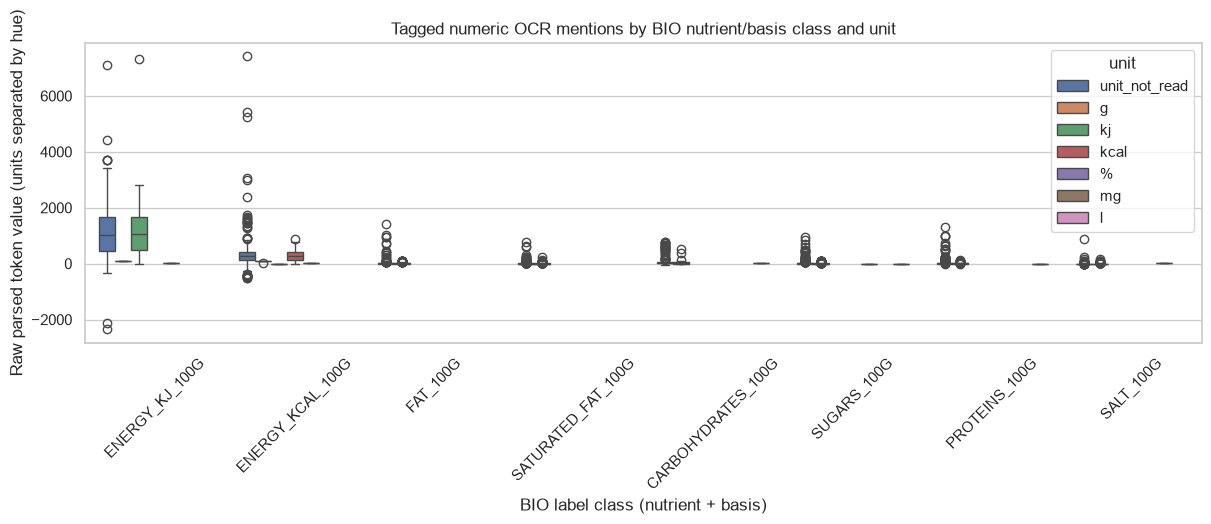

In [14]:
# Summary tables and distribution plots for actual tagged numeric mentions.
if not value_mentions_df.empty:
    value_mentions_df["nutrient_class"] = value_mentions_df["label"].str.replace(r"^[BI]-", "", regex=True)
    value_summary = value_mentions_df.groupby(["nutrient_class", "unit"], dropna=False)["value"].agg(
        mention_count="count", mean="mean", median="median", p25=lambda x: x.quantile(.25), p75=lambda x: x.quantile(.75), max="max"
    ).reset_index()
else:
    value_summary = pd.DataFrame(columns=["nutrient_class", "unit", "mention_count", "mean", "median", "p25", "p75", "max"])
display(value_summary.sort_values("mention_count", ascending=False).head(30) if not value_summary.empty else value_summary)

if not value_mentions_df.empty:
    common_labels = value_mentions_df["nutrient_class"].value_counts().head(8).index.tolist()
    plot_data = value_mentions_df[value_mentions_df["nutrient_class"].isin(common_labels)].copy()
    fig_values, ax_values = plt.subplots(figsize=(12, 5), constrained_layout=True)
    sns.boxplot(data=plot_data, x="nutrient_class", y="value", hue="unit", showfliers=True, ax=ax_values)
    ax_values.set_title("Tagged numeric OCR mentions by BIO nutrient/basis class and unit")
    ax_values.set_xlabel("BIO label class (nutrient + basis)")
    ax_values.set_ylabel("Raw parsed token value (units separated by hue)")
    ax_values.tick_params(axis="x", rotation=45)
    plt.show()


## 5. Analyze categorical metadata

Brands, product categories, and packaging fields are not present in the Part 2 feature schema. Available categorical variables include official split, barcode/image IDs, annotation batch, checked status, and image/table-type flags. The following summaries report those actual fields only.

In [5]:
metadata_categories = ["split", "batch", "checked", "usda_table", "nutrition_text", "no_nutrition_table", "image_id"]
categorical_summaries = {}
for column in metadata_categories:
    if column not in examples_df:
        continue
    counts = examples_df[column].fillna("<missing>").astype(str).value_counts(dropna=False)
    categorical_summaries[column] = counts.rename_axis(column).reset_index(name="examples")
    print(f"{column}: {examples_df[column].nunique(dropna=False)} observed values")
    display(categorical_summaries[column].head(20))

print("Not in Part 2 schema: brand, product category, product name, package type, structured nutrient table.")

split: 2 observed values


,split,examples
0,train,2884
1,test,199


batch: 44 observed values


,batch,examples
0,batch-31,97
1,batch-12,94
2,batch-23,94
3,batch-7,94
4,batch-8,93
5,batch-35,93
6,batch-3,92
7,batch-33,92
8,batch-36,92
9,batch-19,92


checked: 2 observed values


,checked,examples
0,True,3081
1,False,2


... (5 outputs left out)

,no_nutrition_table,examples
0,False,3082
1,True,1


image_id: 34 observed values


,image_id,examples
0,2,1350
1,4,437
2,3,407
3,5,244
4,6,155
5,1,109
6,7,108
7,8,55
8,9,53
9,10,32


Not in Part 2 schema: brand, product category, product name, package type, structured nutrient table.


## 6. Check relationships and possible leakage

Product relationships are assessed using barcode-level grouping and official split labels. Numeric token values can be summarized by BIO class and split, but because values are not all row-linked to nutrient-name entities, a conventional nutrient correlation matrix or brand/category subgroup analysis is not valid for this dataset.

In [6]:
barcode_quality = examples_df.assign(_valid=examples_df["barcode"].map(valid_barcode))
barcode_counts = barcode_quality.groupby("split").agg(
    rows=("split", "size"),
    unique_valid_barcodes=("_valid", "nunique"),
    missing_or_invalid_barcodes=("_valid", lambda values: int(values.isna().sum())),
    duplicate_barcode_rows=("_valid", lambda values: int(values.notna().sum() - values.nunique())),
).reset_index()
barcode_split = barcode_quality.loc[barcode_quality["_valid"].notna()].groupby("_valid")["split"].nunique()
leaked_barcodes = set(barcode_split[barcode_split > 1].index)
print("Barcode quality by official split:")
display(barcode_counts)
print({"distinct_barcodes_across_splits": int(len(leaked_barcodes)), "barcode_split_leakage": int(len(leaked_barcodes))})

if not value_mentions_df.empty:
    split_value_summary = value_mentions_df.groupby(["split", "label", "unit"], dropna=False)["value"].agg(count="count", median="median", p95=lambda x: x.quantile(.95)).reset_index()
    display(split_value_summary.head(40))

# Annotation-flag proportions by split (metadata only).
flag_columns = [column for column in ["checked", "usda_table", "nutrition_text", "no_nutrition_table"] if column in examples_df]
flag_summary = examples_df.groupby("split")[flag_columns].agg(lambda series: f"{int(series.fillna(False).astype(bool).sum())}/{len(series)}").reset_index()
display(flag_summary)

Barcode quality by official split:


,split,rows,unique_valid_barcodes,missing_or_invalid_barcodes,duplicate_barcode_rows
0,test,199,199,0,0
1,train,2884,2884,0,0


{'distinct_barcodes_across_splits': 0, 'barcode_split_leakage': 0}


,split,label,unit,count,median,p95
0,test,B-ADDED_SUGARS_SERVING,g,2,8.000,13.400
1,test,B-CALCIUM_100G,mg,1,186.000,186.000
2,test,B-CALCIUM_100G,unit_not_read,4,120.000,485.500
3,test,B-CALCIUM_SERVING,unit_not_read,2,138.500,174.050
4,test,B-CARBOHYDRATES_100G,g,76,9.250,80.500
5,test,B-CARBOHYDRATES_100G,unit_not_read,103,15.000,76.690
6,test,B-CARBOHYDRATES_SERVING,g,27,11.000,28.800
7,test,B-CARBOHYDRATES_SERVING,unit_not_read,42,13.350,71.850
8,test,B-CHOLESTEROL_SERVING,mg,2,0.000,0.000
9,test,B-CHOLESTEROL_SERVING,unit_not_read,2,0.000,0.000


,split,checked,usda_table,nutrition_text,no_nutrition_table
0,test,199/199,7/199,37/199,0/199
1,train,2882/2884,133/2884,494/2884,1/2884


## 7. Identify outliers and suspicious values

Flag invalid sequence alignment, malformed boxes/labels, empty OCR, extreme token values, and images reporting an implausible shape. These are review flags only: raw annotations are preserved, and no legitimate observations are trimmed.

In [7]:
quality_summary = {
    "rows": int(len(examples_df)),
    "missing_valid_barcode": int(examples_df["barcode"].eq("").sum()),
    "sequence_alignment_failures": int((~examples_df["sequence_alignment_ok"]).sum()),
    "bbox_shape_failures": int((~examples_df["bbox_shape_ok"]).sum()),
    "bbox_coordinate_range_failures": int((~examples_df["bbox_coordinates_0_to_1000"]).sum()),
    "invalid_label_ids": int((~examples_df["label_ids_valid"]).sum()),
    "empty_token_sequences": int(examples_df["token_count"].eq(0).sum()),
    "empty_box_sequences": int(examples_df["bbox_count"].eq(0).sum()),
    "empty_tag_sequences": int(examples_df["tag_count"].eq(0).sum()),
    "rows_with_non_o_tags": int(sequence_df["non_o_tag_count"].gt(0).sum()),
    "rows_with_no_non_o_tags": int(sequence_df["non_o_tag_count"].eq(0).sum()),
}
quality_summary["missing_fraction_of_rows"] = {
    column: round(float(examples_df[column].isna().mean()), 6)
    for column in examples_df.columns
}
print(json.dumps(quality_summary, indent=2, ensure_ascii=False))

suspicious_rows = []
for record in records:
    reasons = []
    if len(record["_tokens"]) != len(record["_boxes"]) or len(record["_tokens"]) != len(record["_ner_tags"]):
        reasons.append("unaligned_sequence_lengths")
    if not record["barcode"]:
        reasons.append("missing_or_invalid_barcode")
    if record["token_count"] == 0:
        reasons.append("empty_ocr_tokens")
    if record["image_width"] and record["image_height"] and (record["image_width"] <= 0 or record["image_height"] <= 0):
        reasons.append("invalid_image_dimensions")
    for idx, token in enumerate(record["_tokens"]):
        parsed = parse_loose_number(token)
        if parsed and (abs(parsed[0]) > 10000):
            reasons.append(f"extreme_numeric_token_at_{idx}")
    if reasons:
        suspicious_rows.append({"split": record["split"], "barcode": record["barcode"], "image_id": record["image_id"], "token_count": record["token_count"], "reasons": ";".join(reasons)})
suspicious_df = pd.DataFrame(suspicious_rows, columns=["split", "barcode", "image_id", "token_count", "reasons"])
print("Rows flagged for review (not removed):", len(suspicious_df))
display(suspicious_df.head(30))

{
  "rows": 3083,
  "missing_valid_barcode": 0,
  "sequence_alignment_failures": 0,
  "bbox_shape_failures": 0,
  "bbox_coordinate_range_failures": 0,
  "invalid_label_ids": 0,
  "empty_token_sequences": 0,
  "empty_box_sequences": 0,
  "empty_tag_sequences": 0,
  "rows_with_non_o_tags": 3083,
  "rows_with_no_non_o_tags": 0,
  "missing_fraction_of_rows": {
    "split": 0.0,
    "barcode_raw": 0.0,
    "barcode": 0.0,
    "image_id": 0.0,
    "image_url_present": 0.0,
    "ocr_url_present": 0.0,
    "batch": 0.0,
    "label_studio_id": 0.0,
    "checked": 0.0,
    "usda_table": 0.0,
    "nutrition_text": 0.0,
    "no_nutrition_table": 0.0,
    "comment_present": 0.0,
    "token_count": 0.0,
    "bbox_count": 0.0,
    "tag_count": 0.0,
    "sequence_alignment_ok": 0.0,
    "bbox_shape_ok": 0.0,
    "bbox_coordinates_0_to_1000": 0.0,
    "label_ids_valid": 0.0,
    "image_width": 0.0,
    "image_height": 0.0
  }
}
Rows flagged for review (not removed): 652


,split,barcode,image_id,token_count,reasons
0,train,3831051012073,5,120,extreme_numeric_token_at_118;extreme_numeric_t...
1,train,4032600122086,5,58,extreme_numeric_token_at_57
2,train,3760051586843,1,230,extreme_numeric_token_at_205
3,train,2924546003104,2,137,extreme_numeric_token_at_89;extreme_numeric_to...
4,train,2309613005128,2,66,extreme_numeric_token_at_64
5,train,3760029248100,1,185,extreme_numeric_token_at_136;extreme_numeric_t...
6,train,20008208,2,40,extreme_numeric_token_at_34
7,train,4008122004292,2,83,extreme_numeric_token_at_77
8,train,3608580039341,3,65,extreme_numeric_token_at_63
9,train,2113097004450,2,164,extreme_numeric_token_at_159;extreme_numeric_t...


## Flagged-token investigation and conservative categorization

The rule is exact: a record is flagged if at least one parsed numeric OCR token has `abs(value) > 10,000` (`12000` → flagged; `250` → not flagged). These 652 records are review candidates, not confirmed errors. The next cell retains the original OCR token, a local text window, and the full token sequence, then applies conservative evidence-based categories. Category assignments are heuristic only; no image was inspected for this classification and no source annotations are changed. When evidence is insufficient, the result stays **Uncertain — insufficient evidence**. The exclusive record-level counts below sum to the flagged-record total; the detail table is token-level.

In [28]:
REVIEW_THRESHOLD = 10_000
REVIEW_CATEGORIES = [
    "Barcode/product identifier",
    "Potential OCR recognition error",
    "Legitimate large nutritional value",
    "Numeric parsing error",
    "Other text (dates, batch numbers, etc.)",
    "Uncertain — insufficient evidence",
]


def classify_flagged_token(record: dict, token_index: int, parsed_value: float) -> tuple[str, str]:
    tokens = record["_tokens"]
    tags = record["_ner_tags"]
    token = tokens[token_index]
    local_tokens = tokens[max(0, token_index - 4): min(len(tokens), token_index + 5)]
    context = " ".join(local_tokens)
    token_digits = "".join(character for character in token if character.isdigit())
    window_digits = "".join(character for item in local_tokens for character in item if character.isdigit())
    barcode = record.get("barcode", "")

    if barcode and token_digits and barcode in window_digits and token_digits in barcode:
        return "Barcode/product identifier", "Barcode digits are present across the local OCR-token window."

    explicit_non_nutrition_cue = re.search(
        r"(?i)\b(lot(?:e)?|batch|exp(?:iry)?|best before|use by|date|fecha|caducidad|validez)\b",
        context,
    )
    compact = re.sub(r"\s+", "", token)
    looks_like_date = bool(re.fullmatch(r"(?:19|20)\d{2}[-./]?(?:0[1-9]|1[0-2])[-./]?(?:0[1-9]|[12]\d|3[01])", compact))
    if explicit_non_nutrition_cue or looks_like_date:
        return "Other text (dates, batch numbers, etc.)", "Explicit lot/date cue or date-shaped token is present; interpretation remains heuristic."

    if token_index < len(tags):
        label = id_to_label.get(tags[token_index], "O")
        entity = label[2:] if label.startswith(("B-", "I-")) else ""
        nearby = " ".join(tokens[max(0, token_index - 3): min(len(tokens), token_index + 4)]).casefold()
        unit_present = bool(re.search(r"(?i)\b(kj|kcal|mg|mcg|µg|ug|g)\b", nearby))
        nutrient_context = bool(re.search(r"(?i)\b(energy|energie|fat|mati[eè]res grasses|protein|proteines|carbohydrate|glucides|sugar|sucres|salt|sel|sodium|fiber|fibre)\b", nearby))
        if ("_100G" in entity or "_SERVING" in entity) and unit_present and nutrient_context:
            return "Legitimate large nutritional value", "Nutrient/basis BIO label plus nearby unit and nutrient text; still requires visual verification."

    if re.search(r"\d[A-Za-z][\dA-Za-z]", token) and any(character.isdigit() for character in token):
        return "Potential OCR recognition error", "Flagged token interleaves digits and letters; OCR confusion is plausible but unverified."

    return "Uncertain — insufficient evidence", "No sufficiently specific context signal; manual image review would be needed."


flagged_token_rows = []
flagged_record_rows = []
for source_record in records:
    record_categories = []
    record_flagged_token_indexes = []
    source_tokens = source_record["_tokens"]
    for token_index, raw_token in enumerate(source_tokens):
        parsed_token = parse_loose_number(raw_token)
        if not parsed_token or abs(parsed_token[0]) <= REVIEW_THRESHOLD:
            continue
        category, evidence = classify_flagged_token(source_record, token_index, parsed_token[0])
        record_categories.append(category)
        record_flagged_token_indexes.append(token_index)
        context_tokens = source_tokens[max(0, token_index - 4): min(len(source_tokens), token_index + 5)]
        token_label = id_to_label.get(source_record["_ner_tags"][token_index], "UNKNOWN") if token_index < len(source_record["_ner_tags"]) else "UNKNOWN"
        flagged_token_rows.append({
            "split": source_record["split"],
            "barcode": source_record["barcode"],
            "image_id": source_record["image_id"],
            "token_index": token_index,
            "original_ocr_token": raw_token,
            "parsed_value": parsed_token[0],
            "bio_label": token_label,
            "category": category,
            "evidence_note": evidence,
            "surrounding_original_ocr_text": " ".join(context_tokens),
            "full_original_ocr_text": " ".join(source_tokens),
            "manual_visual_verification": False,
        })
    if record_flagged_token_indexes:
        exclusive_category = record_categories[0] if len(set(record_categories)) == 1 else "Uncertain — insufficient evidence"
        flagged_record_rows.append({
            "split": source_record["split"],
            "barcode": source_record["barcode"],
            "image_id": source_record["image_id"],
            "token_count": source_record["token_count"],
            "flagged_token_indexes": ";".join(map(str, record_flagged_token_indexes)),
            "category": exclusive_category,
            "manual_visual_verification": False,
            "full_original_ocr_text": " ".join(source_tokens),
        })

flagged_token_df = pd.DataFrame(flagged_token_rows)
flagged_record_df = pd.DataFrame(flagged_record_rows)
flag_category_summary = (
    flagged_record_df["category"].value_counts().reindex(REVIEW_CATEGORIES, fill_value=0)
    .rename_axis("category").reset_index(name="flagged_records")
)
print("Threshold examples:", {"12000": abs(12000) > REVIEW_THRESHOLD, "250": abs(250) > REVIEW_THRESHOLD})
print("Flagged records:", len(flagged_record_df), "| prior EDA count:", len(suspicious_df))
assert len(flagged_record_df) == len(suspicious_df), "Investigation and original review-flag counts differ."
print("Exclusive heuristic categories (sum equals flagged records):")
display(flag_category_summary)
print("Representative token-level evidence (heuristic; none manually image-verified):")
display(flagged_token_df.groupby("category", group_keys=False).head(1)[[
    "split", "barcode", "image_id", "original_ocr_token", "parsed_value", "bio_label", "category", "surrounding_original_ocr_text", "full_original_ocr_text", "evidence_note", "manual_visual_verification"
]])

Threshold examples: {'12000': True, '250': False}
Flagged records: 652 | prior EDA count: 652
Exclusive heuristic categories (sum equals flagged records):


,category,flagged_records
0,Barcode/product identifier,77
1,Potential OCR recognition error,2
2,Legitimate large nutritional value,0
3,Numeric parsing error,0
4,"Other text (dates, batch numbers, etc.)",13
5,Uncertain — insufficient evidence,560


Representative token-level evidence (heuristic; none manually image-verified):


,split,barcode,image_id,original_ocr_token,parsed_value,bio_label,category,surrounding_original_ocr_text,full_original_ocr_text,evidence_note,manual_visual_verification
0,train,3831051012073,5,831051,831051.0,O,Barcode/product identifier,zasebnega standarda »Pridelano/proizvedeno\n...,iselne og HOM 3aCKTeH MACTA di cui acid...,Barcode digits are present across the local OC...,False
2,train,4032600122086,5,90000\n,90000.0,O,Uncertain — insufficient evidence,Eiweiß Salz\n (8400KJ/2000 kcal).\n 90000\n,Für trische Kartoffe bereitetes Produkt p...,No sufficiently specific context signal; manua...,False
3,train,3760051586843,1,18111617\n,18111617.0,O,"Other text (dates, batch numbers, etc.)",: N lot : 18111617\n A consommer de pref...,Noolam .\n ONS LE BON GOU\n Lamelles de K...,Explicit lot/date cue or date-shaped token is ...,False
213,train,8424771050989,3,45950-4TOlo)\n,45950.0,O,Potential OCR recognition error,233-236 Casarrubios del Monte 45950-4TOlo)\n,Emcesa\n MACAR RONES 9OLON . *****..... ....,Flagged token interleaves digits and letters; ...,False


## 8. Build summary statistics tables

Report split-level and overall sequence summaries, metadata missingness, barcode/duplicate counts, label support, and numeric spans parsed from tagged tokens. Categorical tables describe annotation metadata, not product market composition.

In [8]:
numeric_sequence_summary = sequence_df.groupby("split")["token_count"].agg(
    examples="count", mean_tokens="mean", median_tokens="median", p25=lambda x: x.quantile(.25), p75=lambda x: x.quantile(.75), min_tokens="min", max_tokens="max"
).reset_index()
metadata_missingness = pd.DataFrame({
    "field": examples_df.columns,
    "missing_count": [int(examples_df[column].isna().sum()) for column in examples_df.columns],
    "missing_fraction": [float(examples_df[column].isna().mean()) for column in examples_df.columns],
}).sort_values("missing_fraction", ascending=False)
label_support = pd.DataFrame([
    {"label_id": label_id, "label": label, "train_token_support": sum(sum(tag == label_id for tag in r["_ner_tags"]) for r in split_rows.get("train", [])), "test_token_support": sum(sum(tag == label_id for tag in r["_ner_tags"]) for r in split_rows.get("test", []))}
    for label_id, label in sorted(id_to_label.items())
])
print("OCR token sequence length summary:")
display(numeric_sequence_summary)
print("Most-missing metadata and structural fields:")
display(metadata_missingness.head(20))
print("BIO label token support by split:")
display(label_support.sort_values("train_token_support", ascending=False).head(30))

OCR token sequence length summary:


,split,examples,mean_tokens,median_tokens,p25,p75,min_tokens,max_tokens
0,test,199,110.854271,76.0,46.0,133.5,22,1112
1,train,2884,99.559639,75.0,44.0,120.0,16,1041


Most-missing metadata and structural fields:


,field,missing_count,missing_fraction
0,split,0,0.0
1,barcode_raw,0,0.0
2,barcode,0,0.0
3,image_id,0,0.0
4,image_url_present,0,0.0
5,ocr_url_present,0,0.0
6,batch,0,0.0
7,label_studio_id,0,0.0
8,checked,0,0.0
9,usda_table,0,0.0


BIO label token support by split:


,label_id,label,train_token_support,test_token_support
0,0,O,236271,18353
67,67,B-PROTEINS_100G,2686,188
27,27,B-FAT_100G,2676,188
37,37,B-CARBOHYDRATES_100G,2672,187
17,17,B-SUGARS_100G,2670,184
1,1,B-ENERGY_KJ_100G,2658,186
65,65,B-SATURATED_FAT_100G,2646,185
61,61,B-SALT_100G,2613,187
55,55,B-ENERGY_KCAL_100G,2521,177
56,56,I-ENERGY_KCAL_100G,2177,153


## 9. Create visual EDA plots

Visualize token sequence lengths by split, BIO class support, metadata flags, and image aspect-ratio distribution where dimension metadata is returned. These plots do not require or fetch image files.

**Token support definition and calculation:** token support for a BIO label is the count of OCR token positions assigned that label, separately for train and test. It is **not** a count of products or complete nutrient entities. For example:

| OCR token | BIO label | Contribution |
|---|---|---:|
| Fat | O | 1 token to O |
| 18 | B-FAT | 1 token to B-FAT |
| g | I-FAT | 1 token to I-FAT |

Thus `B-FAT` and `I-FAT` each receive one token of support; they do not count as one finished nutrient row. `O` means outside any annotated entity. It is excluded from the main top-20 label chart because its much larger support would compress the nutrient-label bars; its train/test counts are reported separately.

**How to read the plots:**
- **OCR token sequence length:** each observation is an image; the x-axis is its number of OCR tokens and the y-axis is the number of images in that bin. Train has 2,884 images and test has 199, so the train distribution is larger.
- **Top BIO labels:** bars count token positions assigned a label in each split. `B-` marks the beginning of an entity and `I-` continues it.
- **Annotation metadata flags:** counts of examples marked true/false for `checked`, `usda_table`, `nutrition_text`, and `no_nutrition_table`; these describe annotation status or table type, not extraction accuracy.
- **Image aspect ratio:** width divided by height, from dimension metadata only. Values below 1 are portrait, near 1 are square, and above 1 are landscape. No image pixels are downloaded.

Token support per label/split = count of OCR token positions assigned that BIO label; it is not a product/entity count.
O token support: {'train': 236271, 'test': 18353}


,OCR token,BIO label,Support contribution
0,Fat,O,1 token to O
1,18,B-FAT,1 token to B-FAT
2,g,I-FAT,1 token to I-FAT


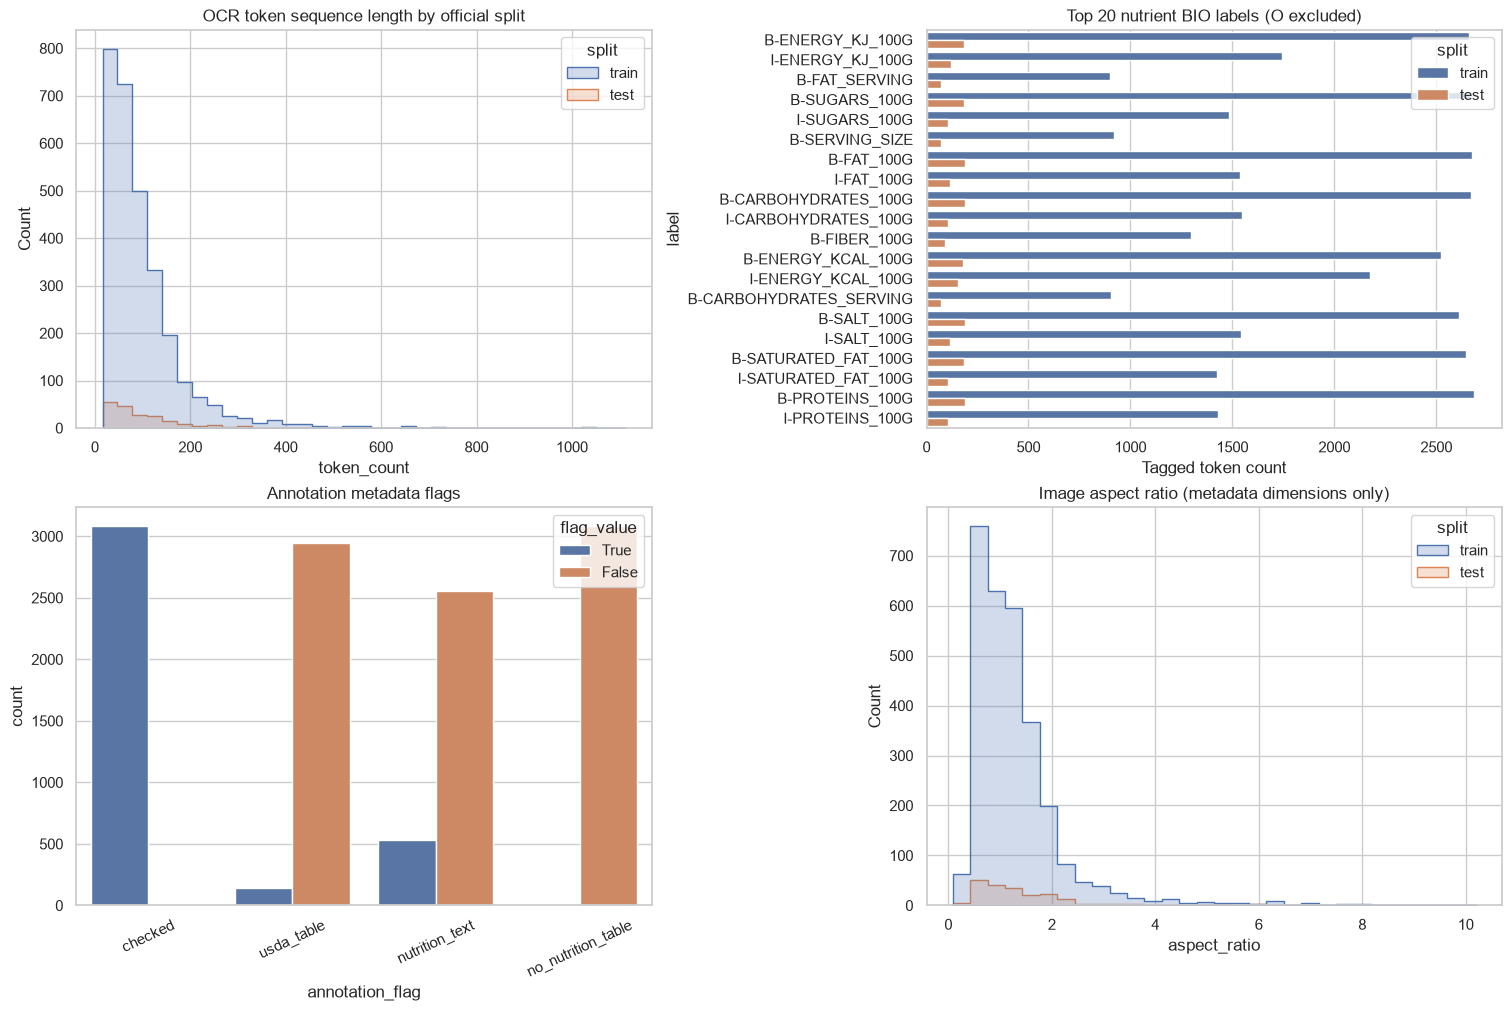

In [30]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
sns.histplot(data=sequence_df, x="token_count", hue="split", bins=35, element="step", stat="count", common_norm=False, ax=axes[0, 0])
axes[0, 0].set_title("OCR token sequence length by official split")

# O dominates token counts by design, so plot it separately and focus the chart on
# the 20 most-supported nutrient BIO labels to avoid a distorted axis/overlap.
non_o_support = label_support[label_support["label"] != "O"].copy()
non_o_support["total_support"] = non_o_support["train_token_support"] + non_o_support["test_token_support"]
top_labels = non_o_support.nlargest(20, "total_support")["label"].tolist()
label_plot = non_o_support[non_o_support["label"].isin(top_labels)].melt(
    id_vars=["label_id", "label"],
    value_vars=["train_token_support", "test_token_support"],
    var_name="split",
    value_name="token_support",
)
label_plot["split"] = label_plot["split"].map({"train_token_support": "train", "test_token_support": "test"})
sns.barplot(data=label_plot, y="label", x="token_support", hue="split", ax=axes[0, 1])
axes[0, 1].set_title("Top 20 nutrient BIO labels (O excluded)")
axes[0, 1].set_xlabel("Tagged token count")
print("Token support per label/split = count of OCR token positions assigned that BIO label; it is not a product/entity count.")
print("O token support:", {"train": int(label_support.loc[label_support["label"].eq("O"), "train_token_support"].sum()), "test": int(label_support.loc[label_support["label"].eq("O"), "test_token_support"].sum())})
label_example_df = pd.DataFrame([
    {"OCR token": "Fat", "BIO label": "O", "Support contribution": "1 token to O"},
    {"OCR token": "18", "BIO label": "B-FAT", "Support contribution": "1 token to B-FAT"},
    {"OCR token": "g", "BIO label": "I-FAT", "Support contribution": "1 token to I-FAT"},
])
display(label_example_df)

flag_cols = [c for c in ["checked", "usda_table", "nutrition_text", "no_nutrition_table"] if c in examples_df]
flag_plot = examples_df.melt(id_vars=["split"], value_vars=flag_cols, var_name="annotation_flag", value_name="flag_value")
if not flag_plot.empty:
    flag_plot["flag_value"] = flag_plot["flag_value"].fillna(False).astype(bool).astype(str)
    sns.countplot(data=flag_plot, x="annotation_flag", hue="flag_value", ax=axes[1, 0])
    axes[1, 0].tick_params(axis="x", rotation=25)
axes[1, 0].set_title("Annotation metadata flags")

image_dims = examples_df.dropna(subset=["image_width", "image_height"]).copy()
if not image_dims.empty:
    image_dims["aspect_ratio"] = image_dims["image_width"] / image_dims["image_height"].replace(0, np.nan)
    sns.histplot(data=image_dims, x="aspect_ratio", hue="split", bins=30, element="step", common_norm=False, ax=axes[1, 1])
    axes[1, 1].set_title("Image aspect ratio (metadata dimensions only)")
else:
    axes[1, 1].text(.5, .5, "No dimensions returned in row metadata", ha="center", va="center")
    axes[1, 1].set_axis_off()
plt.show()

# Save a dashboard-ready static figure as well.
fig.savefig(OUTPUT_DIR / "part2_eda_overview.png", dpi=160, bbox_inches="tight")

## 10. Add the separate Part 2 EDA dashboard view

The existing Streamlit app is extended with a dedicated **Part 2 Dataset EDA** navigation view. It reads only the cached summary tables and overview plot created by this notebook; it does not fetch from Hugging Face when the dashboard starts.

In [31]:
# Dashboard-ready aggregates: persisted as derived EDA artifacts, not a linked/training dataset.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
examples_df.to_csv(OUTPUT_DIR / "part2_example_metadata.csv", index=False)
label_support.to_csv(OUTPUT_DIR / "part2_label_support.csv", index=False)
metadata_missingness.to_csv(OUTPUT_DIR / "part2_metadata_missingness.csv", index=False)
# Keep one token_count row per image so the dashboard can draw the sequence-length histogram.
sequence_df.to_csv(OUTPUT_DIR / "part2_sequence_summary.csv", index=False)
value_summary.to_csv(OUTPUT_DIR / "part2_tagged_value_summary.csv", index=False)
flagged_record_df.to_csv(OUTPUT_DIR / "part2_review_flags.csv", index=False)
flagged_token_df.to_csv(OUTPUT_DIR / "part2_flagged_tokens.csv", index=False)
flag_category_summary.to_csv(OUTPUT_DIR / "part2_review_flag_categories.csv", index=False)
license_id = card_data.get("license") or next(
    (tag.split(":", 1)[1] for tag in hub_metadata.get("tags", []) if tag.startswith("license:")),
    "not specified in API metadata",
)

part2_dashboard_summary = {
    "dataset_id": DATASET_ID,
    "revision": hub_metadata.get("sha"),
    "last_modified": hub_metadata.get("lastModified"),
    "license": license_id,
    "generated_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "split_counts": split_counts,
    "total_rows": int(len(examples_df)),
    "feature_names": feature_names,
    "label_count": int(len(id_to_label)),
    "unique_valid_barcodes": int(examples_df.loc[examples_df["barcode"].ne(""), "barcode"].nunique()),
    "duplicate_barcode_rows": int(barcode_counts["duplicate_barcode_rows"].sum()),
    "barcode_leakage_across_train_test": int(len(leaked_barcodes)),
    "quality_summary": quality_summary,
    "numeric_token_mentions": int(len(value_mentions_df)),
    "suspicious_rows_flagged": int(len(flagged_record_df)),
    "review_flag_threshold_abs_value_gt": REVIEW_THRESHOLD,
    "review_flag_category_counts": dict(zip(flag_category_summary["category"], flag_category_summary["flagged_records"].astype(int))),
    "review_flag_categories_are_heuristic": True,
    "review_flag_categories_manually_verified": False,
    "images_downloaded": 0,
    "caveat": "Token/value label summaries are not structured nutrition facts; nutrient names are generally O. Brand/category/package fields are unavailable. Review-flag categories are conservative heuristics, not visual verification.",
}
(OUTPUT_DIR / "part2_eda_summary.json").write_text(json.dumps(part2_dashboard_summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved Part 2 EDA dashboard artifacts:")
for artifact in sorted(OUTPUT_DIR.iterdir()):
    print(" -", artifact.name)

Saved Part 2 EDA dashboard artifacts:
 - part2_eda_overview.png
 - part2_eda_summary.json
 - part2_example_metadata.csv
 - part2_flagged_tokens.csv
 - part2_label_support.csv
 - part2_metadata_missingness.csv
 - part2_review_flag_categories.csv
 - part2_review_flags.csv
 - part2_sequence_summary.csv
 - part2_tagged_value_summary.csv


## 11. Reusable EDA functions

The API page reader, barcode validator, numeric token parser, schema metadata, and aggregation objects above are reusable in this notebook. The dashboard consumes only the written summaries and cached plot, keeping API calls and image access out of Streamlit.

In [16]:
def summarize_part2(records: list[dict], labels: dict[int, str]) -> dict:
    """Small reusable, no-image summary helper for official split row objects."""
    output = Counter()
    split_barcode_sets = {}
    for record in records:
        output[f"rows_{record['split']}"] += 1
        output["tokens_total"] += record["token_count"]
        output["alignment_failures"] += int(not record["sequence_alignment_ok"])
        output["invalid_boxes"] += int(not record["bbox_shape_ok"])
        output["invalid_label_ids"] += int(not record["label_ids_valid"])
        for tag in record["_ner_tags"]:
            output[f"label_{labels.get(tag, 'UNKNOWN')}"] += 1
    for split in {record["split"] for record in records}:
        split_barcode_sets[split] = {record["barcode"] for record in records if record["split"] == split and record["barcode"]}
    output["train_test_barcode_intersection"] = len(split_barcode_sets.get("train", set()) & split_barcode_sets.get("test", set()))
    return dict(output)

print("Reusable function smoke test:")
print(json.dumps(summarize_part2(records, id_to_label), indent=2, ensure_ascii=False)[:2500])

Reusable function smoke test:
{
  "rows_train": 2884,
  "tokens_total": 309190,
  "alignment_failures": 0,
  "invalid_boxes": 0,
  "invalid_label_ids": 0,
  "label_O": 254624,
  "label_B-ENERGY_KJ_100G": 2844,
  "label_B-ENERGY_KCAL_100G": 2698,
  "label_I-ENERGY_KCAL_100G": 2330,
  "label_B-FAT_100G": 2864,
  "label_B-SATURATED_FAT_100G": 2831,
  "label_I-SATURATED_FAT_100G": 1528,
  "label_B-CARBOHYDRATES_100G": 2859,
  "label_B-SUGARS_100G": 2854,
  "label_B-PROTEINS_100G": 2874,
  "label_B-SALT_100G": 2800,
  "label_B-SERVING_SIZE": 991,
  "label_I-SERVING_SIZE": 569,
  "label_B-ENERGY_KCAL_SERVING": 937,
  "label_B-FAT_SERVING": 970,
  "label_I-FAT_SERVING": 500,
  "label_B-SATURATED_FAT_SERVING": 934,
  "label_I-SATURATED_FAT_SERVING": 465,
  "label_B-TRANS_FAT_SERVING": 154,
  "label_I-TRANS_FAT_SERVING": 48,
  "label_B-CARBOHYDRATES_SERVING": 977,
  "label_I-CARBOHYDRATES_SERVING": 561,
  "label_B-FIBER_SERVING": 737,
  "label_B-SUGARS_SERVING": 964,
  "label_I-SUGARS_SERVING":

## 12. Save artifacts for dashboard and review

Persist only derived metadata summaries, value-by-label summaries, review flags, and plots. No linked dataset or source image files are created.

In [17]:
print("EDA complete. Official train/test annotations were inspected descriptively only; no test labels were used to tune rules.")
print("Open the Streamlit app and choose the 'Part 2 Dataset EDA' navigation view to explore cached reports.")
print("Summary JSON:", OUTPUT_DIR / "part2_eda_summary.json")

EDA complete. Official train/test annotations were inspected descriptively only; no test labels were used to tune rules.
Open the Streamlit app and choose the 'Part 2 Dataset EDA' navigation view to explore cached reports.
Summary JSON: C:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\reports\part2_eda\part2_eda_summary.json
